In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv("C:/Users/Admin/Downloads/Machine-Learning/HomeWork3/course_lead_scoring_2026.csv")

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [5]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['number_of_courses_viewed', 'annual_income', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0)

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance

In [7]:
from sklearn.metrics import roc_auc_score, roc_curve

In [8]:
df.dtypes[df.dtypes != 'object'].index

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='object')

In [9]:
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])

    if auc < 0.5:
        auc = roc_auc_score(y_train, df_train[c])

    print('%16s, %.3f' % (c, auc))

number_of_courses_viewed, 0.723
   annual_income, 0.608
interaction_count, 0.765
      lead_score, 0.788


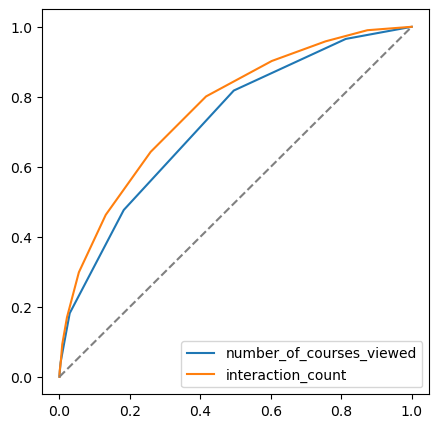

In [10]:
plt.figure(figsize=(5, 5))

fpr, tpr,_ = roc_curve(
    y_train, df_train.number_of_courses_viewed
)
plt.plot(fpr, tpr, label='number_of_courses_viewed')

fpr, tpr,_ = roc_curve(
    y_train, df_train.interaction_count
)
plt.plot(fpr, tpr, label='interaction_count')

plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.legend()
plt.show()

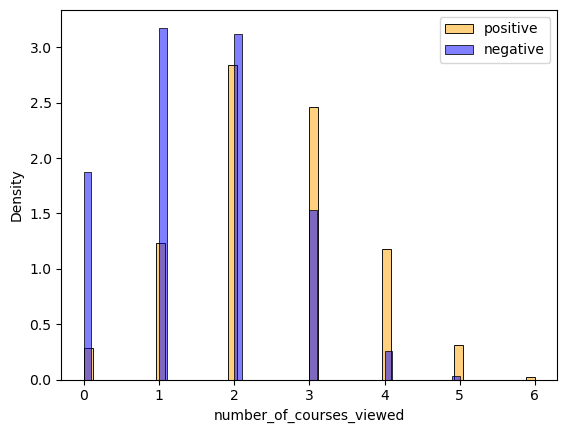

In [11]:
sns.histplot(
    df_train.number_of_courses_viewed[y_train == 1],
    stat='density', bins=50,
    color='orange', alpha=0.5, label='positive'
)

sns.histplot(
    df_train.number_of_courses_viewed[y_train == 0],
    stat='density', bins=50,
    color='blue', alpha=0.5, label='negative'
)

plt.legend()
plt.show()

```Ans: lead_score```

### Question 2 — Train logistic regression

In [12]:
train_dicts = df_train.to_dict(orient='records')

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val)[:, 1]

print('Validation AUC:', round(roc_auc_score(y_val, y_pred), 3))

Validation AUC: 0.732


### Question 3 — Precision and recall

In [13]:
scores = []

for t in np.linspace(0, 1, 101):
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = y_pred >= t
    predict_negative = y_pred < t

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, precision, recall))

df_scores = pd.DataFrame(
    scores,
    columns=['threshold', 'precision', 'recall']
)

In [14]:
display(df_scores.head(10))

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0
5,0.05,0.586,1.0
6,0.06,0.586,1.0
7,0.07,0.586,1.0
8,0.08,0.586,1.0
9,0.09,0.586,1.0


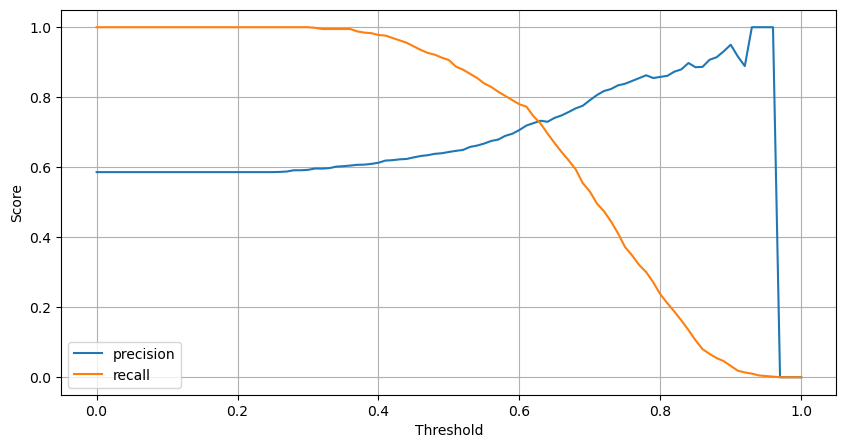

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

In [16]:
df_scores['difference'] = abs(df_scores.precision - df_scores.recall)
valid = df_scores[(df_scores.precision != 0) | (df_scores.recall != 0)]

result = valid.loc[valid.difference.idxmin()]
print(result)

threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64


```Ans: 0.63```

### Question 4: F1 score

In [17]:
df_scores['f1'] = (2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)).fillna(0)

In [18]:
df_scores.loc[df_scores.f1.idxmax()]

threshold     0.410000
precision     0.619048
recall        0.976109
difference    0.357062
f1            0.757616
Name: 41, dtype: float64

```Ans:0.41```

### Question 5: 5-Fold CV

In [19]:
from sklearn.model_selection import KFold

In [20]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx].copy()
    df_val = df_full_train.iloc[val_idx].copy()

    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    df_train = df_train.drop(columns=['converted'])
    df_val = df_val.drop(columns=['converted'])

    dv = DictVectorizer()
    X_train = dv.fit_transform(df_train.to_dict(orient='records'))
    X_val = dv.transform(df_val.to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('AUC Scores:', scores)
print('Standard deviation:', round(np.std(scores),3))

AUC Scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Standard deviation: 0.007


```Ans:0.007```

### Question 6: Hyperparameter Tuning

In [21]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx].copy()
        df_val = df_full_train.iloc[val_idx].copy()

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        df_train = df_train.drop(columns=['converted'])
        df_val = df_val.drop(columns=['converted'])

        dv = DictVectorizer()
        X_train = dv.fit_transform(df_train.to_dict(orient='records'))
        X_val = dv.transform(df_val.to_dict(orient='records'))

        model = LogisticRegression(
            solver='liblinear', C=C, max_iter=1000
        )
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(y_val, y_pred))

    print(f'C={C}: mean={np.mean(scores):.3f}, std={np.std(scores):.3f}')

C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007


```Ans:0.001```